# Quantized INT8 MobileNetV2 Inference Test
This notebook loads the TFLite model and tests it on sample images from the validation set.

2026-03-15 19:23:58.612716: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-15 19:23:58.612987: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-15 19:23:58.650724: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-15 19:23:59.638547: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off,

Found 452 files belonging to 2 classes.
Using 90 files for validation.
Input Type: <class 'numpy.int8'>
Output Type: <class 'numpy.int8'>


E0000 00:00:1773617040.778203   19785 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1773617040.788842   19785 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
/home/osvaldo/Documents/IA+EO/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTER

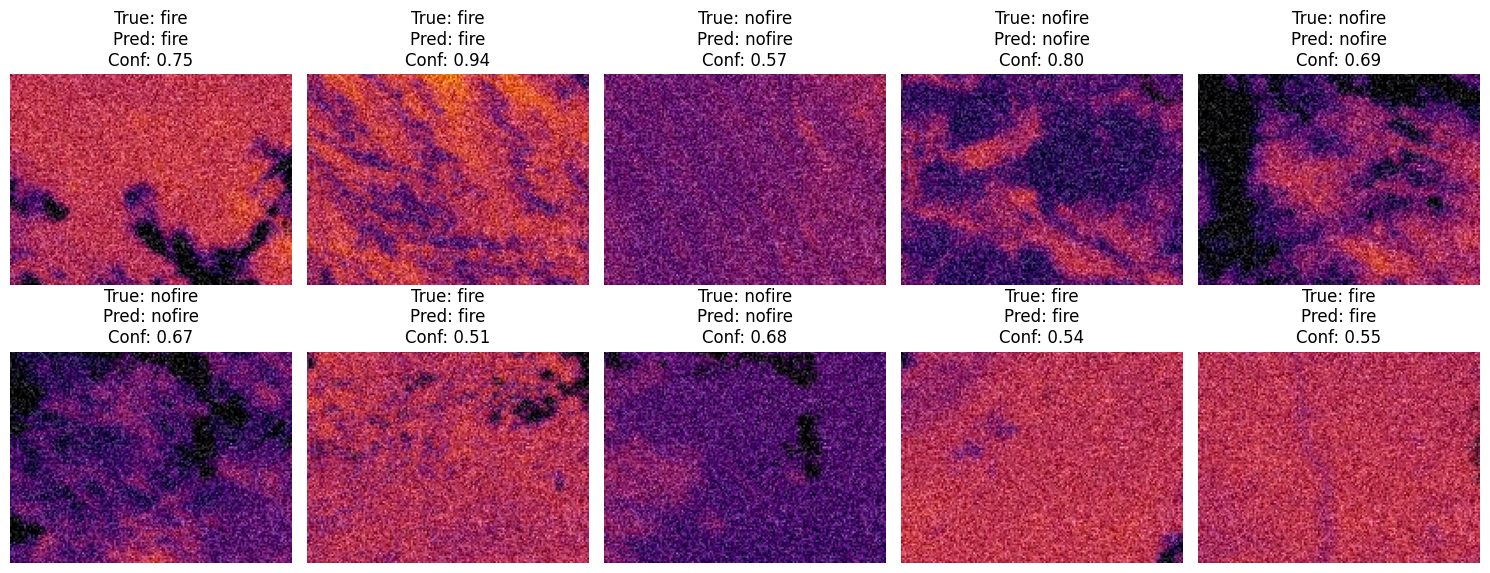


Accuracy on TFLite subset (10 images): 100.00%


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
import os

# configuration
IMG_SIZE = (120, 160)
BATCH_SIZE = 32
DATA_DIR = Path("../data")
MODELS_DIR = Path("../models")

# Load class names
with open(MODELS_DIR / 'classes.json', 'r') as f:
    class_names = json.load(f)

# Load validation dataset to sample images
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

quantized_model_path = MODELS_DIR / "mobilenetv2_classifier_quantized_int8_2.tflite"

# Load the TFLite model and allocate tensors
interpreter = tf.lite.Interpreter(model_path=str(quantized_model_path))
interpreter.allocate_tensors()

# Get input and output tensors
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"Input Type: {input_details[0]['dtype']}")
print(f"Output Type: {output_details[0]['dtype']}")

# Get quantization parameters
input_scale, input_zero_point = input_details[0]['quantization']
output_scale, output_zero_point = output_details[0]['quantization']

def evaluate_tflite_model(dataset, num_samples=10):
    correct = 0
    tested = 0
    
    plt.figure(figsize=(15, 6))
    
    for images, labels in dataset.unbatch().shuffle(100).take(num_samples):
        img = images.numpy()
        true_label = labels.numpy()
        
        # The Keras model used tf.cast(images, tf.float32) for the Keras inference.
        # For INT8 quantization, we need to convert [0, 255] float to int8.
        input_data = img / input_scale + input_zero_point
        input_data = np.clip(input_data, -128, 127).astype(np.int8)
        input_data = np.expand_dims(input_data, axis=0)
        
        interpreter.set_tensor(input_details[0]['index'], input_data)
        interpreter.invoke()
        
        output_data = interpreter.get_tensor(output_details[0]['index'])[0]
        prediction_float = (output_data.astype(np.float32) - output_zero_point) * output_scale
        
        if len(class_names) == 2:
            pred_class = 1 if prediction_float[0] > 0.5 else 0
            confidence = prediction_float[0] if pred_class == 1 else 1 - prediction_float[0]
        else:
            pred_class = np.argmax(prediction_float)
            confidence = prediction_float[pred_class]
            
        if pred_class == true_label:
            correct += 1
        tested += 1
        
        plt.subplot(2, num_samples//2, tested)
        plt.imshow(img.astype(np.uint8))
        plt.title(f"True: {class_names[true_label]}\nPred: {class_names[pred_class]}\nConf: {confidence:.2f}")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()
    
    print(f"\nAccuracy on TFLite subset ({num_samples} images): {correct/tested:.2%}")

evaluate_tflite_model(val_ds, num_samples=10)
